# Does training different chords redistribute the component weights idiosyncratically?

Each participant trains a different set of 4 chords. Even if everyone starts from the same geometry and learns in the
same way (their trained chords become more distinct), the trained component overlaps differently with the chord
components depending on *which* chords are trained, so the fitted weights could shift differently in every participant.

1. **Simulation:** same baseline and same learning effect for everyone, only the trained set differs. How much does the
   change in each component's share differ between trained sets?
2. **Real data:** do participants change the way their own trained set predicts?

In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import scipy.stats as stats
import pingouin as pg
import PcmPy as pcm
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.models as models
import EFC_learningfMRI.vis as vis

base directory found: /cifs/diedrichsen/data/Chord_exp
Atlas directory found: atlases
figure directory found: paper/figures/


In [2]:
# the baseline geometry, the same for everyone: median session-3 weights of the real family fits (L)
fam_comp   = ['identity', 'single finger', 'muscle pattern', 'hand use', 'mean deviation']
chord_comp = fam_comp[1:]
w          = np.array([0.081, 0.052, 0.005, 0.017, 0.004])

# the learning effect, the same for everyone: the participant's own trained chords become more distinct
train = 0.05

# design: 10 runs of the 8 chords; so many voxels that the fit returns the true weights (no noise in the estimate)
n_run, n_vox, noise = 10, 200000, 0.83
cond_vec = np.tile(np.arange(8), n_run)
part_vec = np.repeat(np.arange(n_run), 8)
rng      = np.random.default_rng(0)

## 1. Simulation: what training each set of chords does to the weights

In [3]:
rows = []
for sn, l in itertools.product(gl.participants, (0, train)):
    # baseline on this participant's chord order (its trained chords first), before (l = 0) and after training
    G_dict = models.make_G_dict(sn)
    Gc     = np.array([G_dict[c] for c in fam_comp])
    G      = np.einsum('k,kij->ij', w, Gc) + l * G_dict['trained']

    data = pcm.sim.make_dataset(pcm.FixedModel('G', G), np.array([]), cond_vec, n_channel=n_vox, noise=noise, rng=rng)[0]
    data.obs_descriptors['part_vec'] = part_vec

    # fit the chord components (as component_model.theta_split); share = weight / sum of the weights
    _, theta = pcm.fit_model_individ(data, [pcm.ComponentModel('comp', Gc)], fit_scale=False, fixed_effect='block', verbose=False)
    wts = np.exp(theta[0][:len(fam_comp), 0])
    for c, x in zip(fam_comp, wts / wts.sum()):
        rows.append({'sn': sn, 
                     'trained': l, 
                     'component': c, 
                     'variance': x})

nf = pd.DataFrame(rows) #.pivot_table(index=['sn', 'component'], columns='learn', values='share').reset_index()

nf 
# nf['pred'] = nf[learn] - nf[0]   # change in share caused by training this participant's set of chords

# # one row per participant, one column per component
# pred = nf.pivot(index='sn', columns='component', values='pred').loc[gl.participants]

# pred

,sn,trained,component,variance
0,101,0.00,identity,0.525507
1,101,0.00,single finger,0.313112
2,101,0.00,muscle pattern,0.032561
3,101,0.00,hand use,0.108259
4,101,0.00,mean deviation,0.020562
...,...,...,...,...
155,118,0.05,identity,0.577217
156,118,0.05,single finger,0.222330
157,118,0.05,muscle pattern,0.115457
158,118,0.05,hand use,0.057593


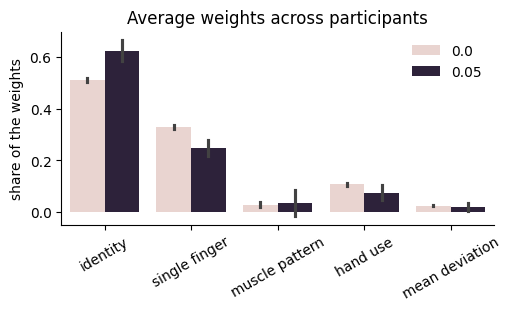

In [4]:
fig, ax = plt.subplots(figsize=(5, 3), constrained_layout=True)

sb.barplot(data=nf, x='component', y='variance', hue='trained', order=fam_comp, errorbar='sd', ax=ax)   # mean and SD across participants

sb.despine(ax=ax)
ax.set_xlabel('')
ax.set_ylabel('share of the weights')
ax.tick_params(axis='x', rotation=30)
ax.legend(frameon=False)
ax.set_title('Average weights across participants')

plt.show()

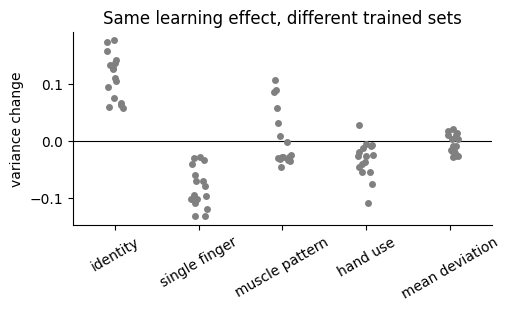

In [5]:
# change in variance caused by training: after minus before, per participant (i.e. per trained set) and component
before = nf[nf.trained == 0].set_index(['sn', 'component']).variance
after  = nf[nf.trained == train].set_index(['sn', 'component']).variance
change = (after - before).rename('predicted var change').reset_index()

fig, ax = plt.subplots(figsize=(5, 3), constrained_layout=True)

sb.stripplot(data=change, x='component', y='predicted var change', order=fam_comp, color='grey', ax=ax)   # one dot per trained set
ax.axhline(0, color='k', lw=.8)

sb.despine(ax=ax)
ax.set_xlabel('')
ax.set_ylabel('variance change')
ax.tick_params(axis='x', rotation=30)
ax.set_title('Same learning effect, different trained sets')

plt.show()

Each dot is one trained set. Without any noise and with the same learning effect, the change differs between trained
sets: muscle pattern goes **up for some sets and down for others**, hand use mostly down, single finger always down but by
different amounts. So a common learning effect is enough to redistribute the weights idiosyncratically.

## 2. Real data: do participants change the way their trained set predicts?

The real change in variance from session 3 (full-data fits of the model family, all runs of a session) is correlated
across participants with the change their trained set predicts. Fits with the chord components only (identity + chord
components), and with the learning components as well (trained + untrained + chord components).

In [6]:
# the two members of the model family (fitted on all runs of a session) to read the weights from
# (written by: python scripts/component_model.py --what family_weight --comp_names <components>)
fits = {'without learning components': ['identity'] + chord_comp,
        'with learning components'   : ['trained', 'untrained'] + chord_comp}   # no identity: trained + untrained add up to it

real = []
for fit, comps in fits.items():
    d = pd.read_csv(os.path.join(gl.baseDir, gl.pcmDir, f'model_family.weight.ROI.glm3.{"+".join(comps)}.tsv'), sep='\t')
    d['fit'] = fit
    real.append(d)
real = pd.concat(real, ignore_index=True)

# variance of each component: its weight over the sum of the weights of the fit; then keep the chord components
total = real.groupby(['fit', 'sn', 'session', 'Hem', 'roi']).weight.transform('sum')
real['variance'] = real.weight / total
real = real[real.component.isin(chord_comp)]

# change from session 3: sorted by session, so the first row of each (fit, Hem, roi, sn, component) is session 3
real = real.sort_values('session')
real['real var change'] = real.variance - real.groupby(['fit', 'Hem', 'roi', 'sn', 'component']).variance.transform('first')

# each row gets the change its participant's trained set predicts (from the simulation above)
real = real.merge(change, on=['sn', 'component'])

real

,component,weight,sn,session,Hem,roi,fit,variance,real var change,predicted var change
0,mean deviation,1.272154e-93,101,3,L,M1,without learning components,8.777292e-92,0.000000e+00,0.017576
1,hand use,1.619552e-03,101,3,L,M1,without learning components,1.117418e-01,0.000000e+00,-0.026927
2,muscle pattern,6.166493e-03,101,3,L,M1,without learning components,4.254603e-01,0.000000e+00,-0.032561
3,single finger,3.042003e-03,101,3,L,M1,without learning components,2.098845e-01,0.000000e+00,-0.032728
4,mean deviation,5.657469e-73,101,3,L,PMv,without learning components,4.775314e-71,0.000000e+00,0.017576
...,...,...,...,...,...,...,...,...,...,...
5371,single finger,2.168050e-03,101,23,L,PMd,without learning components,1.966378e-01,-9.296633e-02,-0.032728
5372,mean deviation,5.276373e-11,101,23,L,SMA,without learning components,3.340938e-09,1.838258e-09,0.017576
5373,hand use,7.796571e-11,101,23,L,SMA,without learning components,4.936698e-09,-5.581293e-01,-0.026927
5374,muscle pattern,4.803255e-11,101,23,L,SMA,without learning components,3.041365e-09,3.041365e-09,-0.032561


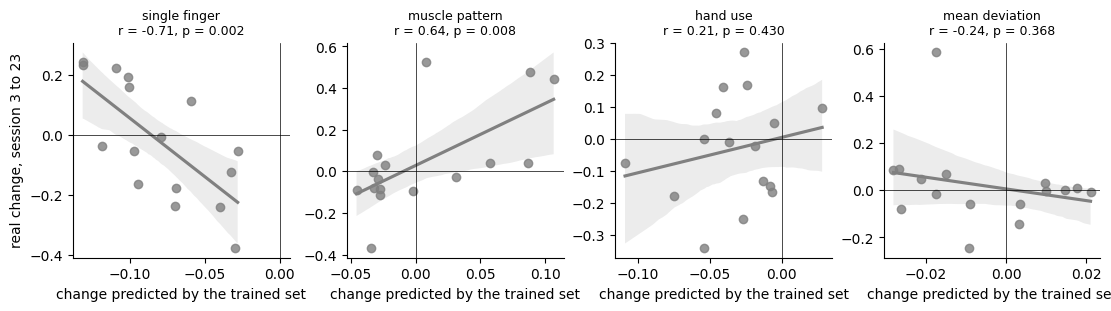

In [7]:
# example: left hemisphere, session 23, chord-only fits, real change averaged over ROIs
x = real[(real.fit == 'without learning components') & (real.Hem == 'L') & (real.session == 23)]
x = x.groupby(['sn', 'component'], as_index=False).mean(numeric_only=True).reset_index()

fig, axs = plt.subplots(1, 4, figsize=(11, 3), constrained_layout=True)

for ax, c in zip(axs, chord_comp):
    xc   = x[x.component == c]
    r, p = stats.pearsonr(xc['predicted var change'], xc['real var change'])
    sb.regplot(data=xc, x='predicted var change', y='real var change', color='grey', ax=ax)   # one dot per participant
    ax.axhline(0, color='k', lw=.5)
    ax.axvline(0, color='k', lw=.5)
    ax.set_title(f'{c}\nr = {r:.2f}, p = {p:.3f}', fontsize=9)
    ax.set_xlabel('change predicted by the trained set')
    ax.set_ylabel('')
    sb.despine(ax=ax)

axs[0].set_ylabel('real change, session 3 to 23')

plt.show()

In [8]:
# all cases: correlation per ROI, then mean r over ROIs and number of ROIs with p < .05 (ROIs are not independent)
rows = []
for (fit, H, roi, c, s), x in real[real.session != 3].groupby(['fit', 'Hem', 'roi', 'component', 'session']):
    r, p = stats.pearsonr(x['real var change'], x['predicted var change'])
    rows.append({'fit': fit, 'Hem': H, 'roi': roi, 'session': s, 'component': c, 'r': r, 'p': p})
corr = pd.DataFrame(rows)

summary = corr.groupby(['fit', 'Hem', 'session', 'component']).agg(r=('r', 'mean'), n_sig=('p', lambda p: (p < .05).sum()))
print(summary.round(2).unstack('component')[['r', 'n_sig']].to_string())

                                               r                                                n_sig                                            
component                               hand use mean deviation muscle pattern single finger hand use mean deviation muscle pattern single finger
fit                         Hem session                                                                                                          
with learning components    L   9           0.00           0.10          -0.10         -0.25        0              0              0             0
                                23          0.08          -0.25           0.56         -0.53        0              0              6             3
                            R   9          -0.02           0.08          -0.03         -0.26        0              0              0             1
                                23          0.24          -0.22           0.55         -0.42        0              0        

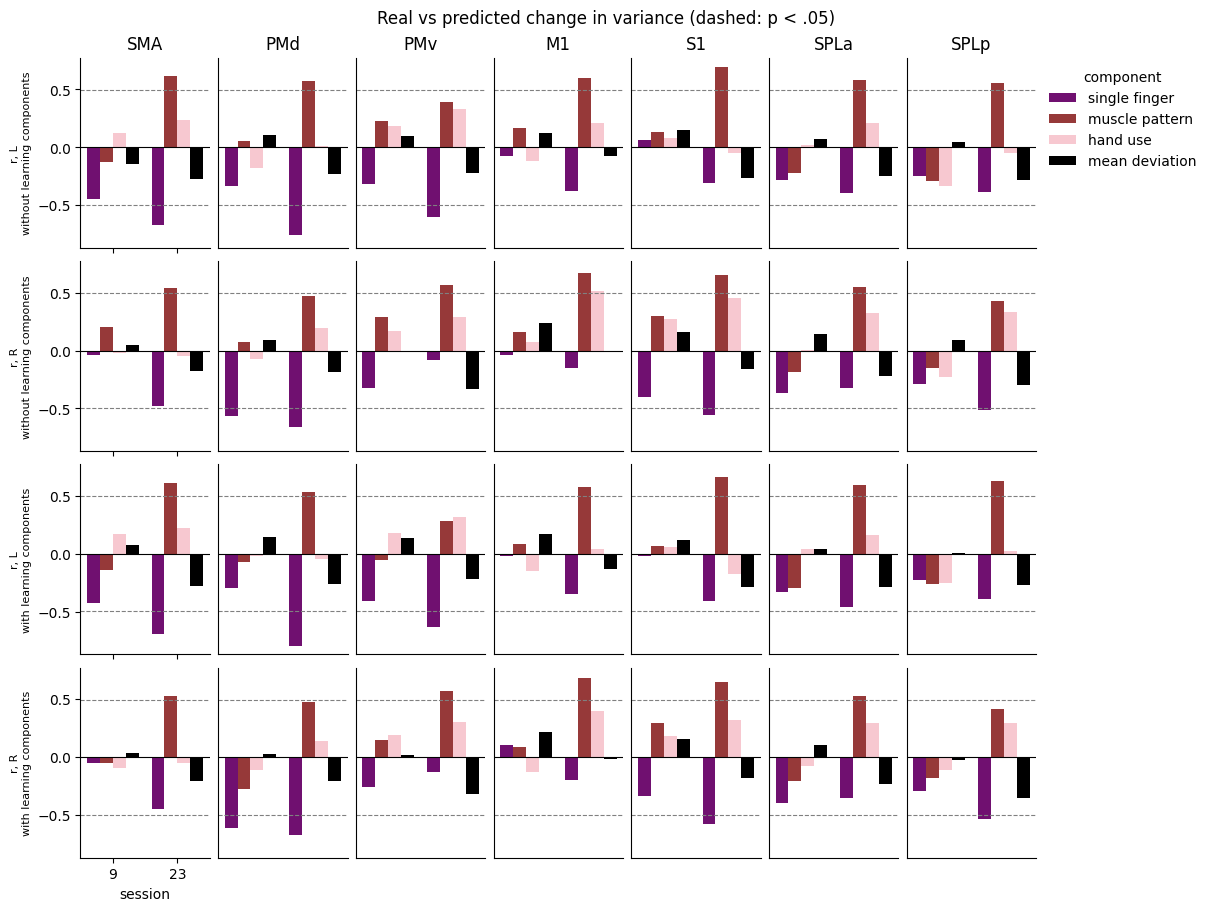

In [9]:
# correlation between real and predicted change, per ROI (columns), for each fit and hemisphere (rows)
rois    = gl.rois['ROI']
palette = {'single finger': 'purple', 'muscle pattern': 'brown', 'hand use': 'pink', 'mean deviation': 'black'}   # as in component_model.ipynb
r_crit  = .497   # |r| above which p < .05 (two-sided) with 16 participants

fig, axs = plt.subplots(4, len(rois), sharey=True, sharex=True, figsize=(12, 9), constrained_layout=True)

for i, (fit, H) in enumerate(itertools.product(fits, 'LR')):
    d = corr[(corr.fit == fit) & (corr.Hem == H)].astype({'session': str})   # session as text: one bar group per session
    vis.plot_im_sess(fig, axs[i], d, rois, y='r', x='session', hue='component',
                     hue_order=chord_comp, palette=palette, kind='bar', native_scale=False, legend=(i == 0))
    for ax in axs[i]:
        ax.axhline(0, color='k', lw=.8)
        ax.axhline(r_crit, color='grey', lw=.8, ls='--')
        ax.axhline(-r_crit, color='grey', lw=.8, ls='--')
    axs[i, 0].set_ylabel(f'r, {H}\n{fit}', fontsize=8)

for ax in axs[1:].ravel():   # ROI names only on the top row
    ax.set_title('')
sb.despine(fig=fig)
axs[-1, 0].set_xlabel('session')
sb.move_legend(axs[0, -1], 'upper left', bbox_to_anchor=(1, 1), frameon=False)

fig.suptitle('Real vs predicted change in variance (dashed: p < .05)')

plt.show()

                                               r                                                n_sig                                            
component                               hand use mean deviation muscle pattern single finger hand use mean deviation muscle pattern single finger
fit                         Hem session                                                                                                          
with learning components    L   9           0.10           0.10          -0.25          0.03        0              0              0             0
                                23          0.18          -0.29           0.55         -0.44        0              0              4             3
                            R   9           0.04           0.01          -0.24         -0.21        0              0              0             1
                                23          0.34          -0.24           0.54         -0.41        0              0        

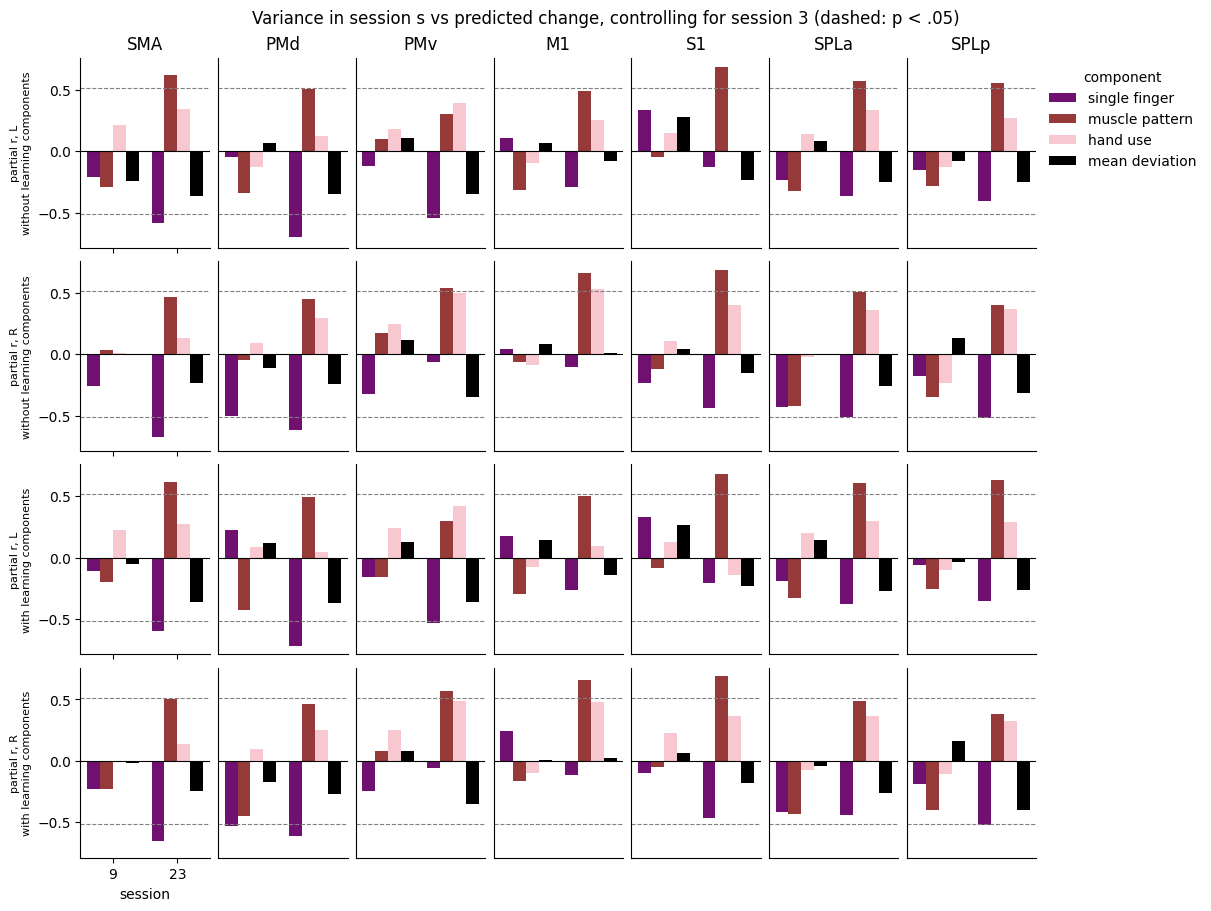

In [10]:
# the same, without the baseline: partial correlation of the variance in session s with the predicted change, controlling
# for the variance in session 3. A chance relation between trained set and session-3 variance (plus regression to the mean)
# can make the change correlate with the prediction; the partial correlation only asks whether participants *move* the way
# their trained set predicts, whatever they started from
real['variance 3'] = real['variance'] - real['real var change']   # the change is the variance minus that of session 3

rows = []
for (fit, H, roi, c, s), x in real[real.session != 3].groupby(['fit', 'Hem', 'roi', 'component', 'session']):
    pc = pg.partial_corr(data=x, x='predicted var change', y='variance', covar='variance 3')
    rows.append({'fit': fit, 'Hem': H, 'roi': roi, 'session': s, 'component': c, 'r': pc['r'].iloc[0], 'p': pc['p_val'].iloc[0]})
pcorr = pd.DataFrame(rows)

summary = pcorr.groupby(['fit', 'Hem', 'session', 'component']).agg(r=('r', 'mean'), n_sig=('p', lambda p: (p < .05).sum()))
print(summary.round(2).unstack('component')[['r', 'n_sig']].to_string())

r_crit = .514   # |partial r| above which p < .05 (two-sided) with 16 participants and one covariate

fig, axs = plt.subplots(4, len(rois), sharey=True, sharex=True, figsize=(12, 9), constrained_layout=True)

for i, (fit, H) in enumerate(itertools.product(fits, 'LR')):
    d = pcorr[(pcorr.fit == fit) & (pcorr.Hem == H)].astype({'session': str})   # session as text: one bar group per session
    vis.plot_im_sess(fig, axs[i], d, rois, y='r', x='session', hue='component',
                     hue_order=chord_comp, palette=palette, kind='bar', native_scale=False, legend=(i == 0))
    for ax in axs[i]:
        ax.axhline(0, color='k', lw=.8)
        ax.axhline(r_crit, color='grey', lw=.8, ls='--')
        ax.axhline(-r_crit, color='grey', lw=.8, ls='--')
    axs[i, 0].set_ylabel(f'partial r, {H}\n{fit}', fontsize=8)

for ax in axs[1:].ravel():   # ROI names only on the top row
    ax.set_title('')
sb.despine(fig=fig)
axs[-1, 0].set_xlabel('session')
sb.move_legend(axs[0, -1], 'upper left', bbox_to_anchor=(1, 1), frameon=False)

fig.suptitle('Variance in session s vs predicted change, controlling for session 3 (dashed: p < .05)')

plt.show()

## Conclusion

At **session 23**, participants change the way their trained set predicts: muscle pattern r ≈ .5 (p < .05 in 3 of 7 ROIs),
hand use r ≈ .2 – .35, in both hemispheres, and whether or not the learning components are in the fit. Single finger
correlates negatively (≈ −.45 to −.55), the opposite of the prediction, so the real learning effect is not exactly "trained
chords more distinct". At **session 9** there is no such relationship for muscle pattern and hand use.

So much of the apparently idiosyncratic reorganisation at session 23 is probably a common learning effect expressed through
each participant's own trained set. Caveats: 16 participants (r = .5 is p ≈ .05 in one ROI), and the prediction assumes a
learning effect shaped like the trained component.